In [30]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

BASE = Path.cwd()

if not (BASE / "vendas.csv").exists():
    raise FileNotFoundError(
        f"Coloque vendas.csv na pasta de execução: {BASE}"
    )

PASTA_GRAFICOS = BASE / "graficos"
PASTA_GRAFICOS.mkdir(exist_ok=True)


def moeda(valor):
    return "R$ " + f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def grafico(serie, arquivo, titulo, eixo_x, eixo_y="", tipo="barh"):
    fig, ax = plt.subplots(figsize=(10, 5.4))

    if tipo == "line":
        serie.plot(ax=ax, kind="line", marker="o", color="#287a78")
    else:
        serie.plot(ax=ax, kind="barh", color="#356d94")

    ax.set(title=titulo, xlabel=eixo_x, ylabel=eixo_y)
    ax.grid(axis="y" if tipo == "line" else "x", alpha=0.2)

    fig.tight_layout()
    fig.savefig(PASTA_GRAFICOS / arquivo, dpi=145, bbox_inches="tight")
    plt.close(fig)

In [31]:
dados = pd.read_csv(
    BASE / "vendas.csv",
    sep=";",
    encoding="utf-8"
)

print("QUESTÃO 1 — EXPLORAÇÃO", dados.shape)

print(dados.dtypes.to_string())

print("Nulos:\n", dados.isna().sum().to_string())

print("Duplicatas exatas:", dados.duplicated().sum())

QUESTÃO 1 — EXPLORAÇÃO (50000, 15)
id_item_venda          int64
id_pedido              int64
data_venda               str
nome_produto             str
categoria_produto        str
quantidade             int64
preco_unitario       float64
desconto             float64
valor_total          float64
nome_cliente             str
cidade_cliente           str
estado_cliente           str
nome_vendedor            str
forma_pagamento          str
status_venda             str
Nulos:
 id_item_venda          0
id_pedido              0
data_venda             0
nome_produto           0
categoria_produto      0
quantidade             0
preco_unitario         0
desconto               0
valor_total            0
nome_cliente           0
cidade_cliente       150
estado_cliente         0
nome_vendedor          0
forma_pagamento        0
status_venda           0
Duplicatas exatas: 150


In [32]:
duplicatas = int(dados.duplicated().sum())

dados = dados.drop_duplicates().copy()

cidades_ausentes = int(dados.cidade_cliente.isna().sum())

dados["cidade_cliente"] = dados.cidade_cliente.fillna("Não informada")

dados["categoria_produto"] = dados.categoria_produto.replace({
    "Informatica": "Informática",
    "Eletronicos": "Eletrônicos"
})

dados["data_venda"] = pd.to_datetime(
    dados.data_venda,
    errors="coerce"
)

calculado = dados.preco_unitario * dados.quantidade - dados.desconto

invalido = (
    dados.data_venda.isna()
    | (dados.quantidade <= 0)
    | (dados.preco_unitario < 0)
    | (dados.desconto < 0)
    | (dados.desconto > dados.preco_unitario * dados.quantidade)
    | dados.valor_total.isna()
    | ((calculado - dados.valor_total).abs() > 0.01)
)

excluidos = dados.loc[invalido].copy()
limpos = dados.loc[~invalido].copy()

vendas = limpos.loc[
    limpos.status_venda.eq("Concluído")
].copy()

vendas["ano"] = vendas.data_venda.dt.year
vendas["mes"] = vendas.data_venda.dt.to_period("M").astype(str)

print(
    "QUESTÃO 2 — ETL:",
    "duplicatas", duplicatas,
    "cidades ausentes", cidades_ausentes,
    "linhas inconsistentes", len(excluidos),
    "linhas válidas", len(limpos)
)

QUESTÃO 2 — ETL: duplicatas 150 cidades ausentes 150 linhas inconsistentes 298 linhas válidas 49552


In [33]:
bruto = (vendas.preco_unitario * vendas.quantidade).sum()

descontos = vendas.desconto.sum()

liquido = vendas.valor_total.sum()

bruto_potencial = (
    limpos.preco_unitario * limpos.quantidade
).sum()

assert abs(bruto - descontos - liquido) < 0.05

print(
    "QUESTÃO 3 — Bruto concluído:", moeda(bruto),
    "Descontos:", moeda(descontos),
    "Líquido realizado:", moeda(liquido),
    "Bruto potencial (todos status):", moeda(bruto_potencial)
)

QUESTÃO 3 — Bruto concluído: R$ 117.190.025,60 Descontos: R$ 6.803.961,55 Líquido realizado: R$ 110.386.064,05 Bruto potencial (todos status): R$ 137.305.431,60


In [34]:
produtos = (
    vendas.groupby("nome_produto")
    .quantidade.sum()
    .nlargest(10)
)

categorias = (
    vendas.groupby("categoria_produto")
    .valor_total.sum()
    .sort_values(ascending=False)
)

mensal = (
    vendas.groupby("mes")
    .valor_total.sum()
    .sort_index()
)

anual = (
    vendas.groupby("ano")
    .valor_total.sum()
    .sort_index()
)

print("QUESTÃO 4 — PRODUTOS\n", produtos.to_string())

print("QUESTÃO 5 — CATEGORIAS\n", categorias.to_string())

print("QUESTÃO 6 — ANOS\n", anual.to_string())

print(
    "Maior mês:", mensal.idxmax(), moeda(mensal.max()),
    "Menor mês:", mensal.idxmin(), moeda(mensal.min())
)

QUESTÃO 4 — PRODUTOS
 nome_produto
Teclado Mecânico RGB        4384
Monitor 27" 4K              4302
Smartphone Premium X        4258
Smartphone Básico Y         4256
Mouse Gamer 10k DPI         4252
Notebook Estudante          4214
Caixa de Som Portátil       4209
Smart TV 55" 4K             4168
Fone de Ouvido Bluetooth    4164
Notebook Ultra Pro          4163
QUESTÃO 5 — CATEGORIAS
 categoria_produto
Informática    59347280.39
Eletrônicos    43603496.62
Acessórios      4481515.00
Áudio           2953772.04
QUESTÃO 6 — ANOS
 ano
2021    36866424.30
2022    36233731.49
2023    37285908.26
Maior mês: 2021-12 R$ 4.164.758,49 Menor mês: 2021-02 R$ 2.361.780,41


In [35]:
vendedores = (
    vendas.groupby("nome_vendedor")
    .agg(
        receita=("valor_total", "sum"),
        pedidos=("id_pedido", "nunique")
    )
    .sort_values("receita", ascending=False)
    .head(5)
)

vendedores["ticket_medio"] = (
    vendedores.receita / vendedores.pedidos
)

print("QUESTÃO 7 — VENDEDORES\n", vendedores.to_string())

QUESTÃO 7 — VENDEDORES
                    receita  pedidos  ticket_medio
nome_vendedor                                    
Carlos Eduardo  8112128.21     1673   4848.851291
Fernanda Alves  7844633.68     1682   4663.872580
Otávio Borges   7681155.83     1603   4791.737885
Diana Souza     7496791.16     1609   4659.285991
Gabriel Gomes   7442974.22     1647   4519.110030


In [36]:
assert (
    vendas.groupby("id_pedido")
    .forma_pagamento.nunique().max() == 1
)

pagamentos = (
    vendas.groupby("forma_pagamento")
    .id_pedido.nunique()
    .sort_values(ascending=False)
)

percentuais = pagamentos / pagamentos.sum() * 100

print("QUESTÃO 8 — PAGAMENTOS (%)\n", percentuais.to_string())

QUESTÃO 8 — PAGAMENTOS (%)
 forma_pagamento
Cartão de Crédito    25.320368
Boleto               25.233837
PIX                  25.209115
Cartão de Débito     24.236681


In [37]:
mapa = {
    "DF": "Centro-Oeste",
    "GO": "Centro-Oeste",
    "BA": "Nordeste",
    "PE": "Nordeste",
    "MG": "Sudeste",
    "RJ": "Sudeste",
    "SP": "Sudeste",
    "PR": "Sul",
    "RS": "Sul",
    "SC": "Sul"
}

vendas["regiao"] = vendas.estado_cliente.map(mapa)

assert vendas.regiao.notna().all(), "Há UFs sem região mapeada"

estados = (
    vendas.groupby("estado_cliente")
    .valor_total.sum()
    .sort_values(ascending=False)
)

regioes = (
    vendas.groupby("regiao")
    .valor_total.sum()
    .sort_values(ascending=False)
)

print("QUESTÃO 9 — ESTADOS\n", estados.to_string())

print("REGIÕES\n", regioes.to_string())

QUESTÃO 9 — ESTADOS
 estado_cliente
PR    11601514.83
SC    11317702.67
SP    11100129.49
BA    11090637.00
MG    11078779.52
DF    11017610.37
RJ    11003544.49
PE    10966909.25
GO    10935427.91
RS    10273808.52
REGIÕES
 regiao
Sul             33193026.02
Sudeste         33182453.50
Nordeste        22057546.25
Centro-Oeste    21953038.28


In [38]:
cruzamento = (
    vendas[vendas.ano.isin([2022, 2023])]
    .groupby(["regiao", "categoria_produto", "ano"])
    .valor_total.sum()
    .unstack(fill_value=0)
)

cruzamento["crescimento_pct"] = np.where(
    cruzamento[2022] > 0,
    (cruzamento[2023] / cruzamento[2022] - 1) * 100,
    np.nan
)

elegiveis = cruzamento[
    (cruzamento[2023] > 0)
    & (cruzamento.crescimento_pct > 0)
]

if elegiveis.empty:
    raise ValueError(
        "Nenhum segmento com crescimento positivo: revisar regra de seleção"
    )

melhor = (
    elegiveis.sort_values(2023, ascending=False).iloc[0]
)

segmento = (
    elegiveis.sort_values(2023, ascending=False).index[0]
)

print(
    "QUESTÃO 11 — Segmento:", segmento,
    "2022:", moeda(melhor[2022]),
    "2023:", moeda(melhor[2023]),
    "Crescimento:", f"{melhor.crescimento_pct:.2f}%"
)

QUESTÃO 11 — Segmento: ('Sudeste', 'Informática') 2022: R$ 5.828.404,18 2023: R$ 6.209.304,80 Crescimento: 6.54%


QUESTÃO 10 — Oito gráficos salvos em C:\Users\Noturno\PycharmProjects\PythonProject\Projeto_Final\Projeto\graficos
CONCLUSÃO — priorizar um piloto de marketing, sujeito a margem, CAC e validação experimental.
Gráfico: 01_produtos.png


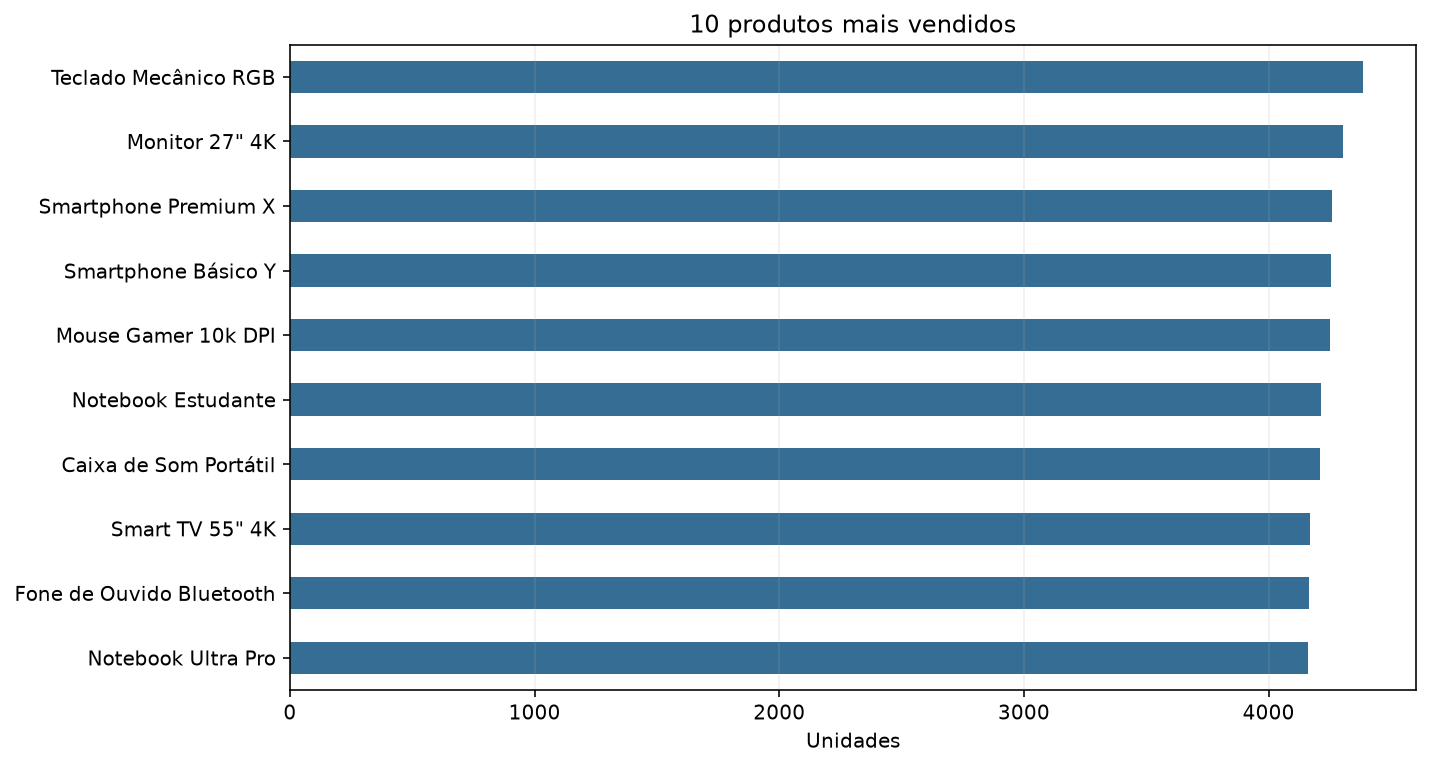

Gráfico: 02_categorias.png


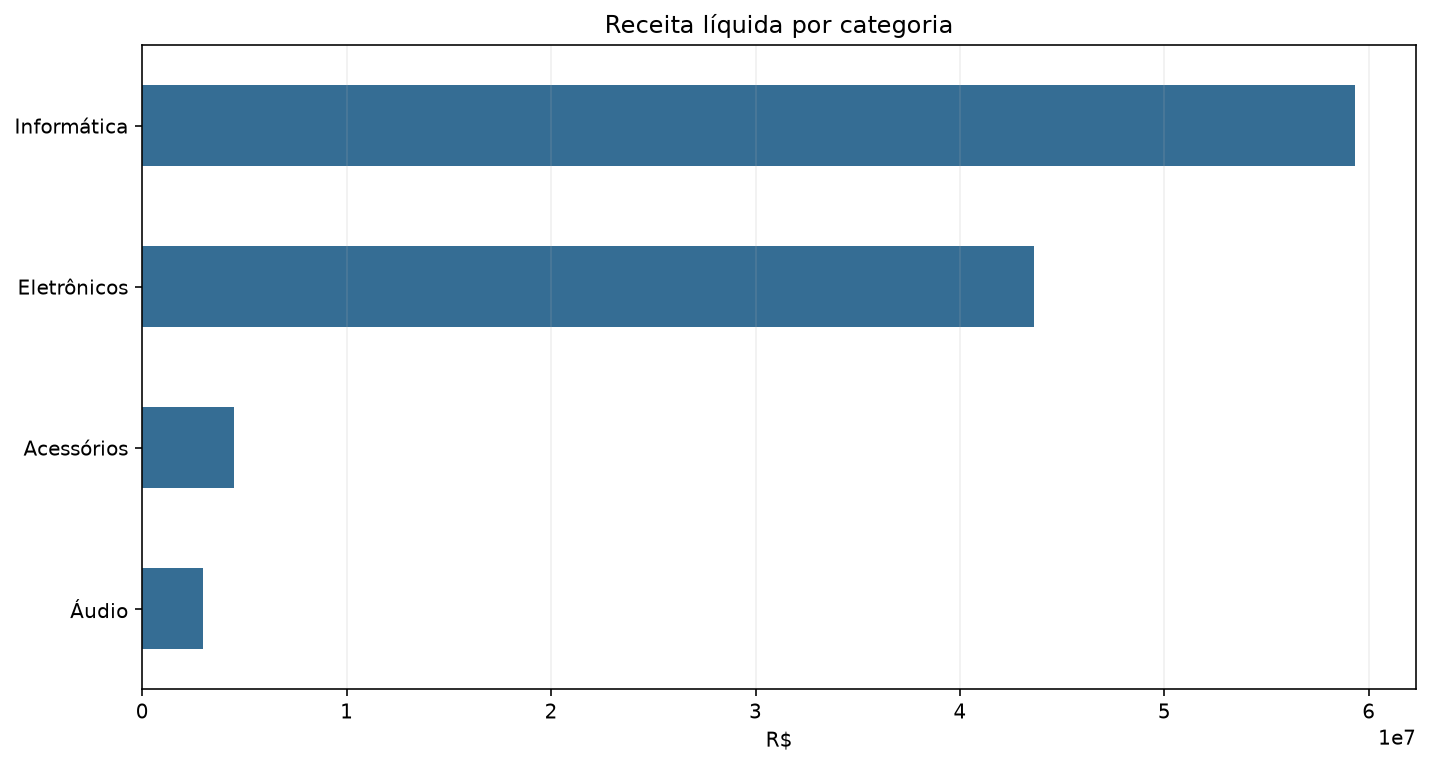

Gráfico: 03_evolucao_mensal.png


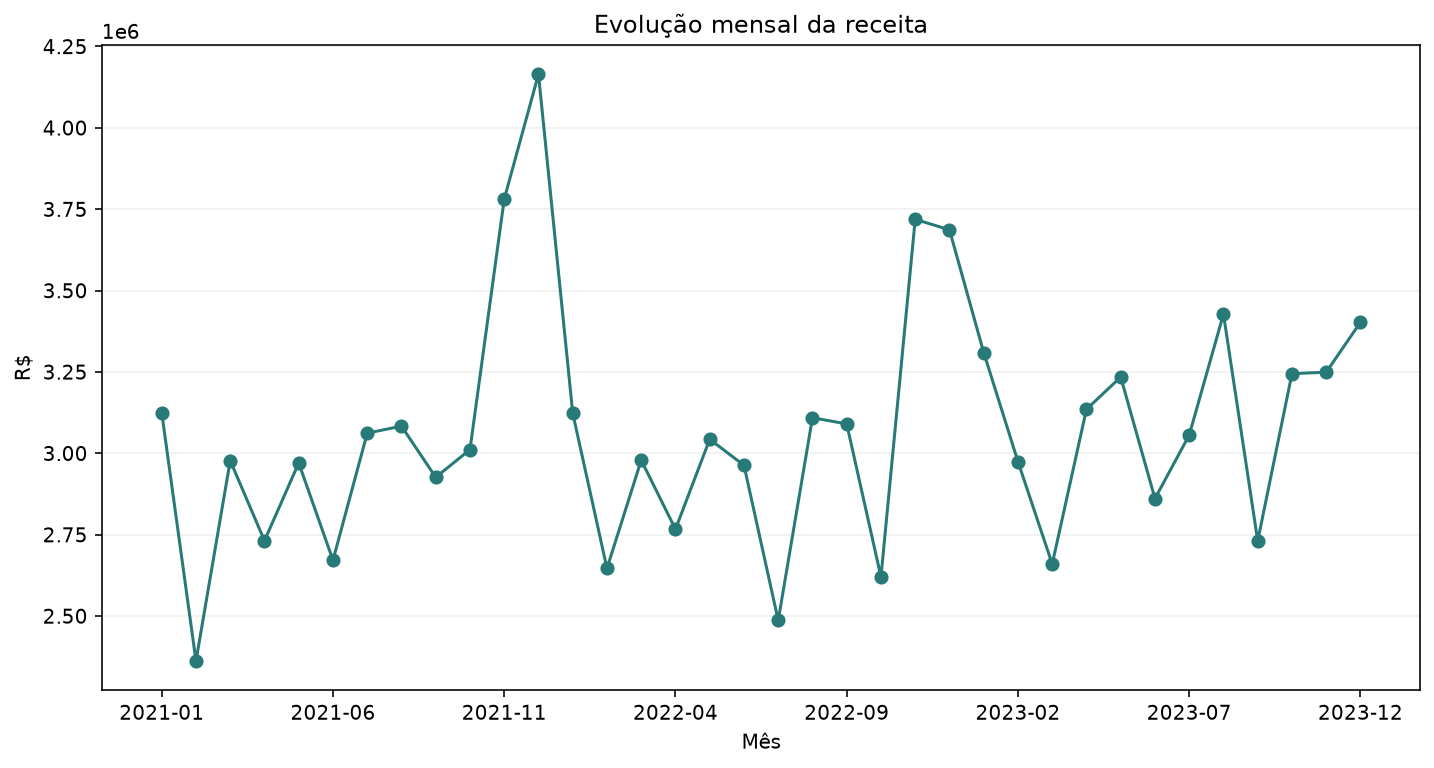

Gráfico: 04_vendedores.png


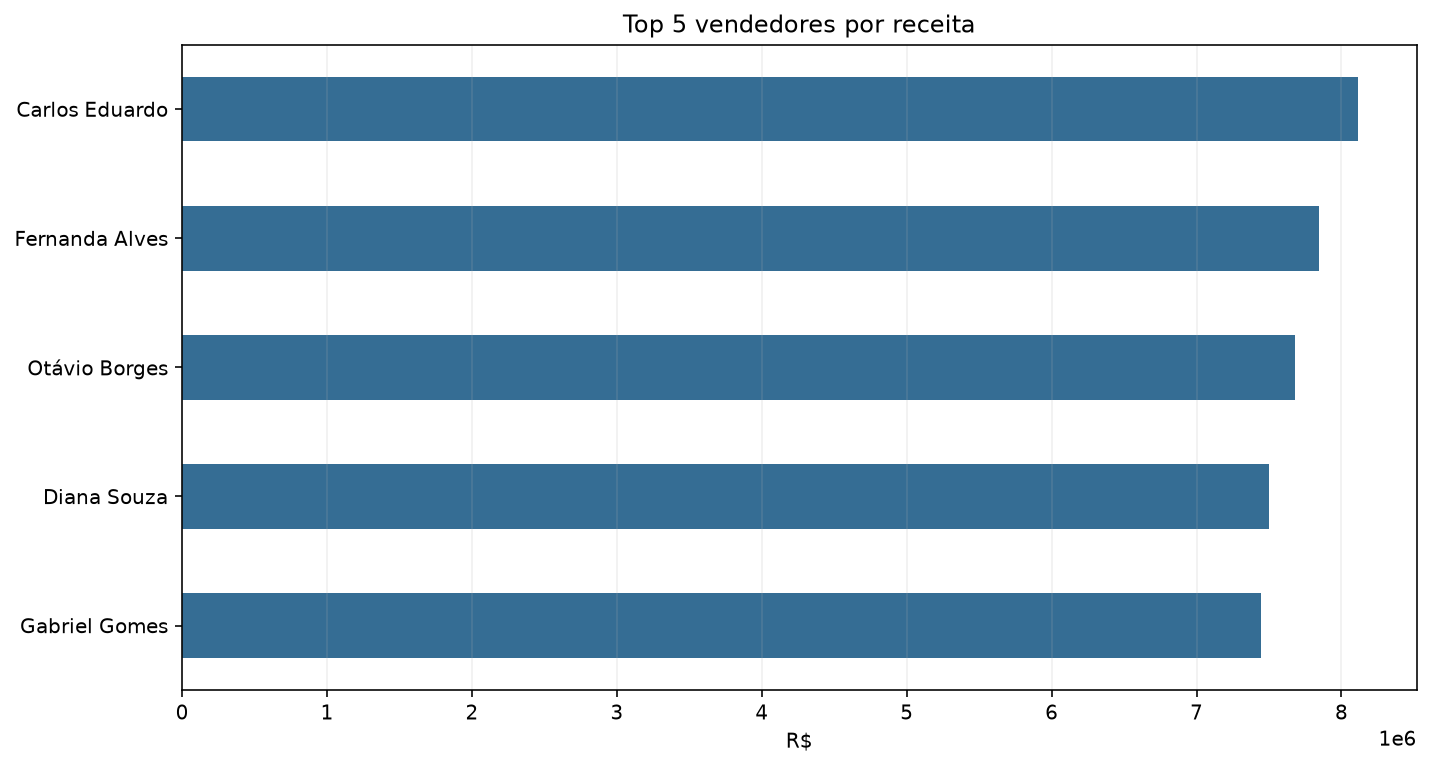

Gráfico: 05_pagamentos.png


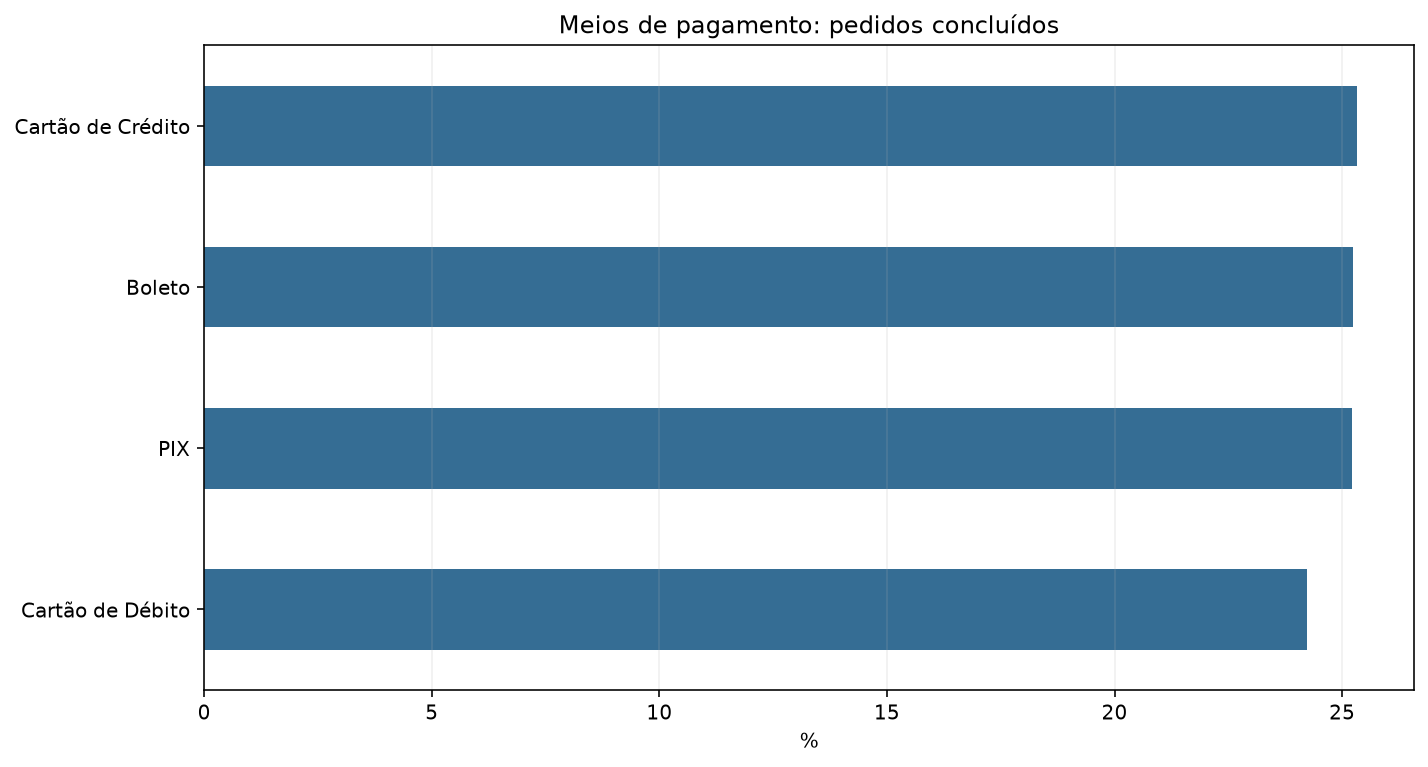

Gráfico: 06_estados.png


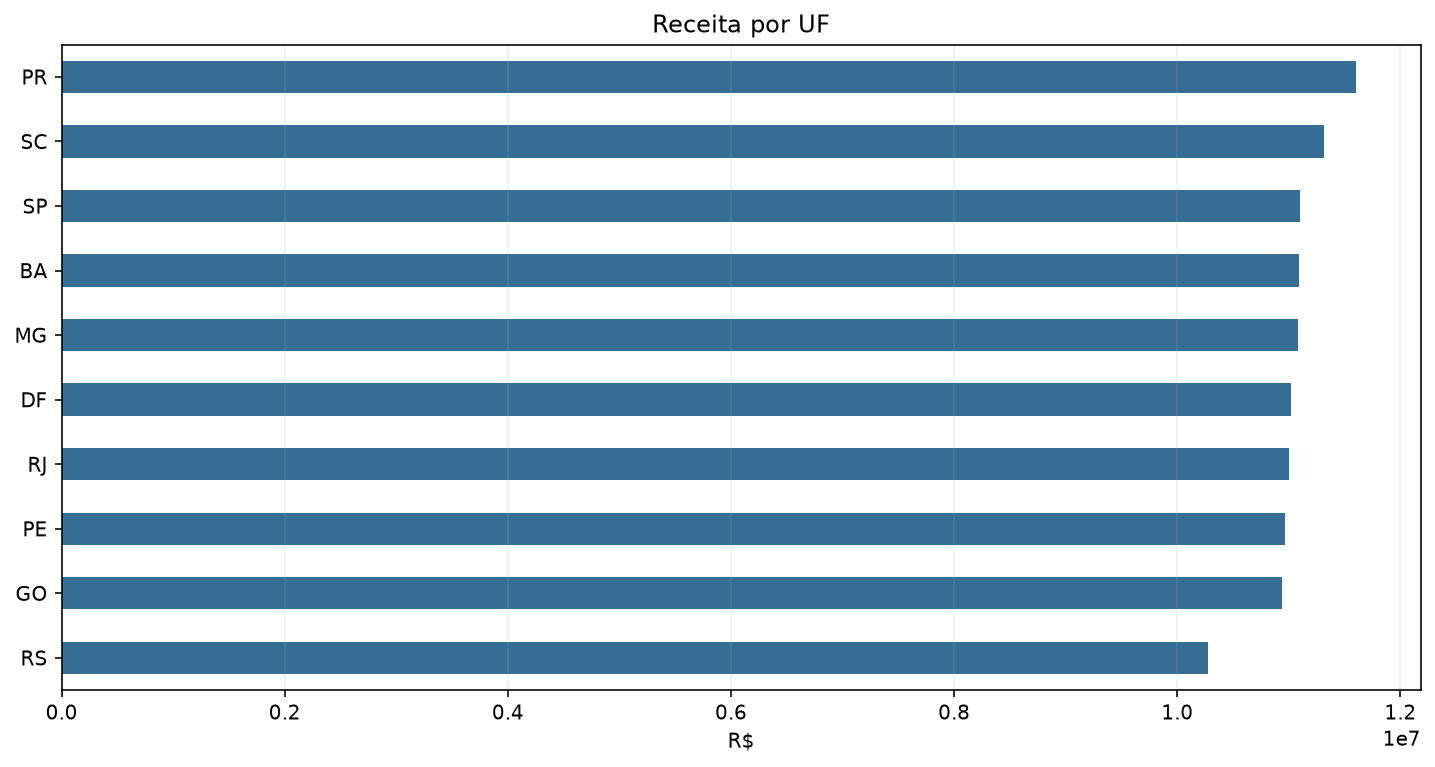

Gráfico: 07_regioes.png


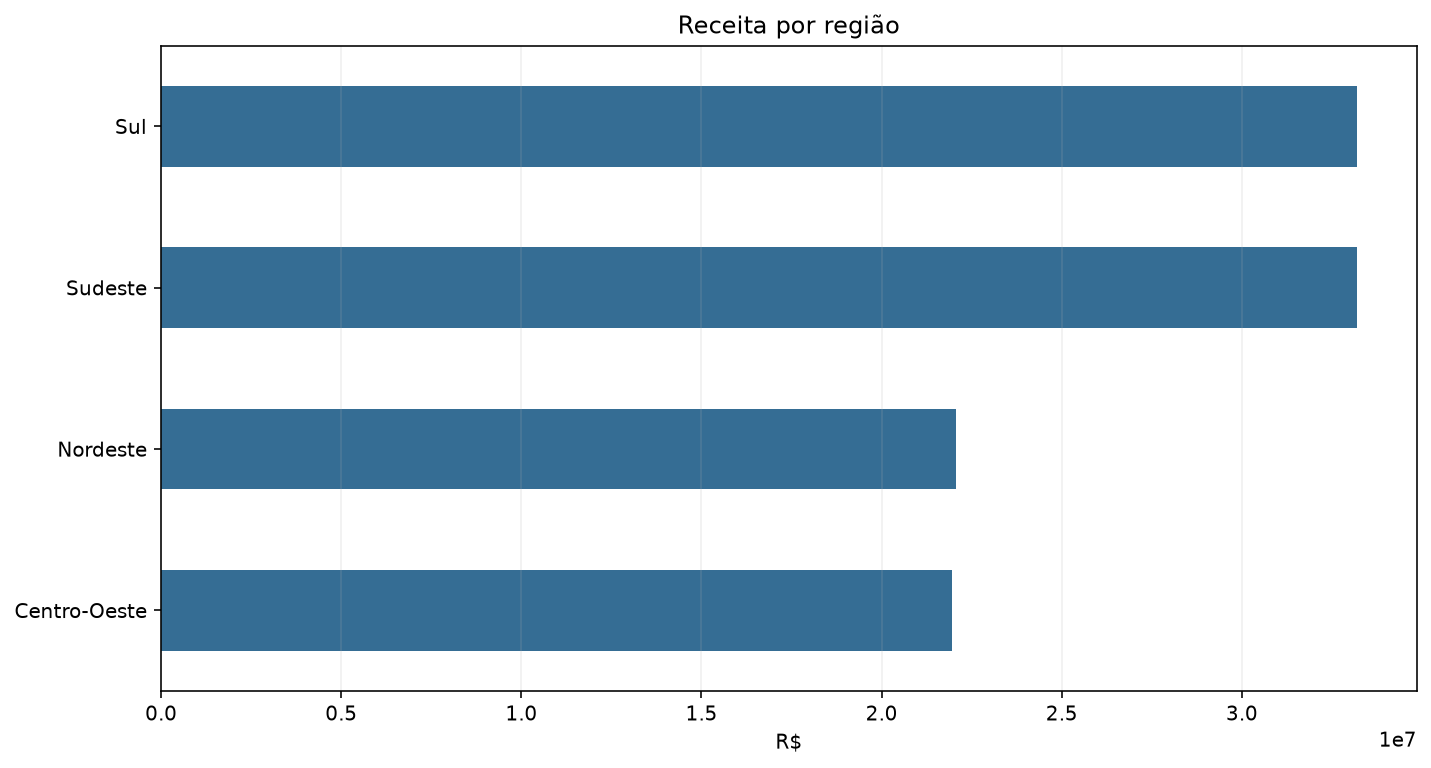

Gráfico: 08_estrategia.png


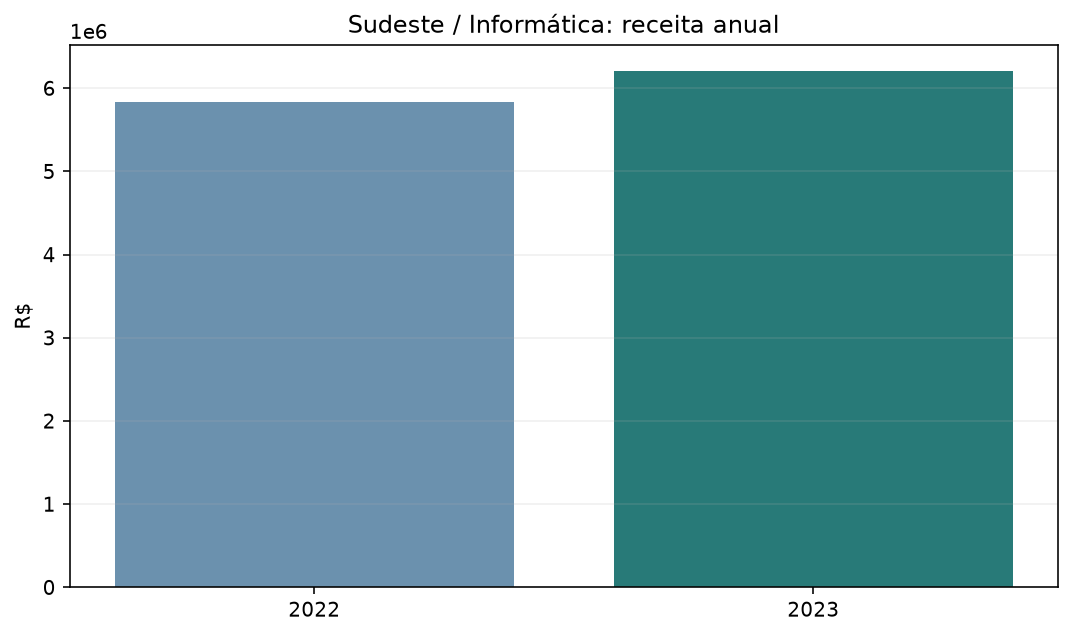

In [39]:
grafico(
    produtos.sort_values(),
    "01_produtos.png",
    "10 produtos mais vendidos",
    "Unidades"
)

grafico(
    categorias.sort_values(),
    "02_categorias.png",
    "Receita líquida por categoria",
    "R$"
)

grafico(
    mensal,
    "03_evolucao_mensal.png",
    "Evolução mensal da receita",
    "Mês",
    "R$",
    "line"
)

grafico(
    vendedores.receita.sort_values(),
    "04_vendedores.png",
    "Top 5 vendedores por receita",
    "R$"
)

grafico(
    percentuais.sort_values(),
    "05_pagamentos.png",
    "Meios de pagamento: pedidos concluídos",
    "%"
)

grafico(
    estados.sort_values(),
    "06_estados.png",
    "Receita por UF",
    "R$"
)

grafico(
    regioes.sort_values(),
    "07_regioes.png",
    "Receita por região",
    "R$"
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.bar(
    ["2022", "2023"],
    [melhor[2022], melhor[2023]],
    color=["#6b91ae", "#287a78"]
)

ax.set(
    title=f"{segmento[0]} / {segmento[1]}: receita anual",
    ylabel="R$"
)

ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    PASTA_GRAFICOS / "08_estrategia.png",
    dpi=145,
    bbox_inches="tight"
)

plt.close(fig)

print("QUESTÃO 10 — Oito gráficos salvos em", PASTA_GRAFICOS)

print(
    "CONCLUSÃO — priorizar um piloto de marketing, "
    "sujeito a margem, CAC e validação experimental."
)

for caminho in sorted(PASTA_GRAFICOS.glob("*.png")):
    print("Gráfico:", caminho.name)
    display(Image(filename=str(caminho), width=720))